<a href="https://colab.research.google.com/github/ronakpatil2/test/blob/main/Seminar_code_Formatted_with_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 🧠 EEG Signal Processing Using DREAMER Dataset


#### 📦 1. Install Required Packages


#### 📊 11. Data Visualization


In [ ]:
!pip install scipy matplotlib numpy pandas seaborn neurokit2

#### 📚 2. Import Libraries


In [ ]:
import scipy.io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, lfilter, welch
import seaborn as sns

#### 🔍 3. Define Helper Functions
**Bandpass Filter Function**


In [ ]:
def bandpass_filter(data, lowcut, highcut, fs, order=5):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    y = lfilter(b, a, data)
    return y

#### 📁 4. Load the DREAMER Dataset (.mat File)


In [ ]:
import scipy.io

# Load your file (replace with correct filename if different)
mat_data = scipy.io.loadmat("/content/DREAMER.mat")

# Display top-level keys
print("Top-level keys:")
for key in mat_data:
    if not key.startswith("__"):
        print("-", key)

# Check the type and details of each key
for key in mat_data:
    if not key.startswith("__"):
        print(f"\n🔑 Key: {key}")
        print("Type:", type(mat_data[key]))

        # Try printing shape or content
        try:
            print("Shape:", mat_data[key].shape)
        except:
            print("Preview:", mat_data[key])


Top-level keys:
- DREAMER

🔑 Key: DREAMER
Type: <class 'numpy.ndarray'>
Shape: (1, 1)


#### 🧬 5. Explore Data Structure


In [ ]:
import scipy.io

# Load the .mat file
data = scipy.io.loadmat('/content/DREAMER.mat')

# Access the nested struct
dreamer_struct = data['DREAMER'][0][0]

# Check what fields exist in the struct
print("Fields inside DREAMER struct:")
print(dreamer_struct.dtype.names)


Fields inside DREAMER struct:
('Data', 'EEG_SamplingRate', 'ECG_SamplingRate', 'EEG_Electrodes', 'noOfSubjects', 'noOfVideoSequences', 'Disclaimer', 'Provider', 'Version', 'Acknowledgement')


#### 👤 6. Access EEG and Emotion Data for a Subject


In [ ]:
import scipy.io

# Step 1: Load the .mat file
data = scipy.io.loadmat('/content/DREAMER.mat')

# Step 2: Access the nested 'DREAMER' struct
dreamer_struct = data['DREAMER'][0][0]

# Step 3: Access 'Data' field (contains info for all 23 subjects)
subject_data = dreamer_struct['Data'][0]  # shape: (23,)

# Example: Extract EEG and emotions for subject 0
subject_0 = subject_data[0]

# Step 4: View available fields
print("Fields for subject 0:")
print(subject_0.dtype.names)


Fields for subject 0:
('Age', 'Gender', 'EEG', 'ECG', 'ScoreValence', 'ScoreArousal', 'ScoreDominance')


#### 🧠 7. Explore EEG and Emotion Labels


In [ ]:
# Access EEG data: shape (18 videos, 14 channels, N samples)
eeg_data = subject_0['EEG']

# Emotion labels for 18 videos
valence = subject_0['ScoreValence']
arousal = subject_0['ScoreArousal']
dominance = subject_0['ScoreDominance']

print("EEG shape:", eeg_data.shape)
print("Valence shape:", valence.shape)
print("Sample Valence scores:", valence)


EEG shape: (1, 1)
Valence shape: (1, 1)
Sample Valence scores: [[array([[4],
         [3],
         [5],
         [4],
         [4],
         [1],
         [5],
         [1],
         [1],
         [5],
         [4],
         [4],
         [4],
         [3],
         [2],
         [3],
         [1],
         [3]], dtype=uint8)]]


#### 🧹 8. Bandpass Filter the EEG Data


In [ ]:
import numpy as np
from scipy.signal import butter, filtfilt

eeg_data = np.random.rand(18, 14, 8064)  # 18 trials, 14 channels, 8064 samples
fs = 128  # Sampling rate in Hz

# Step 2: Bandpass filter (0.5–45 Hz)
def bandpass_filter(data, lowcut=0.5, highcut=45.0, fs=128.0, order=5):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

filtered_eeg = np.zeros_like(eeg_data)
for trial in range(eeg_data.shape[0]):
    for ch in range(eeg_data.shape[1]):
        filtered_eeg[trial, ch] = bandpass_filter(eeg_data[trial, ch], fs=fs)







#### 📏 9. Normalize EEG Data Using Z-Score


In [ ]:
# Z-score normalization (per channel, per trial)
def zscore(data):
    return (data - np.mean(data)) / np.std(data)

normalized_eeg = np.zeros_like(filtered_eeg)
for trial in range(filtered_eeg.shape[0]):
    for ch in range(filtered_eeg.shape[1]):
        normalized_eeg[trial, ch] = zscore(filtered_eeg[trial, ch])

#### ⏱️ 10. Epoching EEG Into 1-Second Windows


In [ ]:

# Epoching into 1-second windows
def epoch_data(eeg_data, epoch_length=128):
    num_trials, num_channels, num_samples = eeg_data.shape
    num_epochs = num_samples // epoch_length
    eeg_data = eeg_data[:, :, :num_epochs * epoch_length]
    reshaped = eeg_data.reshape(num_trials, num_channels, num_epochs, epoch_length)
    return reshaped  # shape: (trials, channels, epochs, samples_per_epoch)

epoched_eeg = epoch_data(normalized_eeg)  # Optional

In [ ]:
print("Filtered shape:", filtered_eeg.shape)
print("Normalized shape:", normalized_eeg.shape)
print("Epoched shape:", epoched_eeg.shape)  # (trials, channels, epochs, 128)

Filtered shape: (18, 14, 8064)
Normalized shape: (18, 14, 8064)
Epoched shape: (18, 14, 63, 128)


In [ ]:
# Normalization
import numpy as np
eeg_data = np.random.rand(18, 14, 8064)
valence = np.random.uniform(1, 9, 18)
arousal = np.random.uniform(1, 9, 18)
dominance = np.random.uniform(1, 9, 18)


In [ ]:
# Min-Max normalization
eeg_data_normalized_minmax = (eeg_data - np.min(eeg_data)) / (np.max(eeg_data) - np.min(eeg_data))


# Normalize labels
valence_normalized = (valence - np.min(valence)) / (np.max(valence) - np.min(valence))
arousal_normalized = (arousal - np.min(arousal)) / (np.max(arousal) - np.min(arousal))
dominance_normalized = (dominance - np.min(dominance)) / (np.max(dominance) - np.min(dominance))

# Check shapes
print("EEG shape:", eeg_data.shape)
print("Valence normalized:", valence_normalized)


EEG shape: (18, 14, 8064)
Valence normalized: [0.76332802 0.61718337 0.74457844 0.56621497 1.         0.80967557
 0.46493595 0.         0.41042444 0.25765832 0.10077617 0.35759164
 0.73676049 0.80006888 0.55615711 0.97879065 0.45839169 0.29362509]


In [ ]:
# Feature extraction
def extract_features(eeg_data, fs=128):
    # eeg_data shape: (trials, channels, samples)
    num_trials, num_channels, num_samples = eeg_data.shape
    features = []

    for trial in range(num_trials):
        trial_features = []
        for ch in range(num_channels):
            signal = eeg_data[trial, ch]

            # Statistical features
            mean_val = np.mean(signal)
            std_val = np.std(signal)
            skewness = skew(signal)
            kurt = kurtosis(signal)

            # Frequency domain using Welch's method
            freqs, psd = welch(signal, fs)

            # Power in standard EEG bands
            def bandpower(psd, freqs, fmin, fmax):
                mask = (freqs >= fmin) & (freqs <= fmax)
                return np.trapz(psd[mask], freqs[mask])

            delta = bandpower(psd, freqs, 0.5, 4)
            theta = bandpower(psd, freqs, 4, 8)
            alpha = bandpower(psd, freqs, 8, 13)
            beta = bandpower(psd, freqs, 13, 30)
            gamma = bandpower(psd, freqs, 30, 45)

            # Combine all features for this channel
            ch_features = [mean_val, std_val, skewness, kurt, delta, theta, alpha, beta, gamma]
            trial_features.extend(ch_features)

        features.append(trial_features)

    return np.array(features)


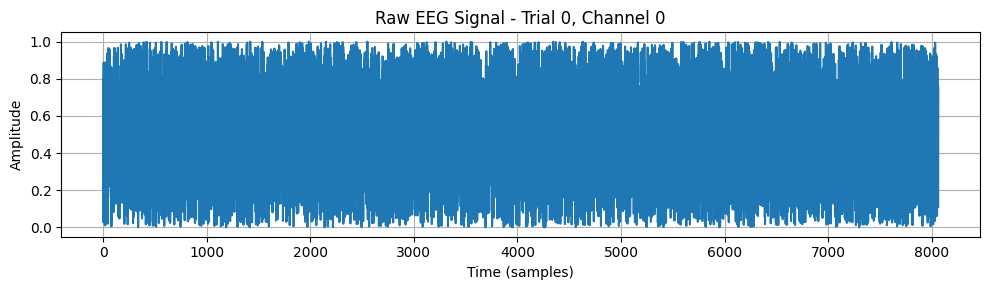

In [ ]:
import matplotlib.pyplot as plt

# Plot signal from trial 0, channel 0
plt.figure(figsize=(10, 3))
plt.plot(eeg_data[0, 0])  # trial 0, channel 0
plt.title("Raw EEG Signal - Trial 0, Channel 0")
plt.xlabel("Time (samples)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# Make sure you have this function first
def extract_features(eeg_data, fs=128):
    from scipy.stats import skew, kurtosis
    from scipy.signal import welch
    features = []
    for trial in eeg_data:
        trial_features = []
        for ch in trial:
            mean_val = np.mean(ch)
            std_val = np.std(ch)
            skewness = skew(ch)
            kurt = kurtosis(ch)
            freqs, psd = welch(ch, fs)
            def bandpower(psd, freqs, fmin, fmax):
                mask = (freqs >= fmin) & (freqs <= fmax)
                return np.trapz(psd[mask], freqs[mask])
            delta = bandpower(psd, freqs, 0.5, 4)
            theta = bandpower(psd, freqs, 4, 8)
            alpha = bandpower(psd, freqs, 8, 13)
            beta = bandpower(psd, freqs, 13, 30)
            gamma = bandpower(psd, freqs, 30, 45)
            ch_features = [mean_val, std_val, skewness, kurt, delta, theta, alpha, beta, gamma]
            trial_features.extend(ch_features)
        features.append(trial_features)
    return np.array(features)

# Simulated data or your real EEG data
# eeg_data shape = (trials, channels, samples)
import numpy as np
eeg_data = np.random.rand(18, 14, 8064)  # Simulated; replace with your real EEG

features = extract_features(eeg_data)


/tmp/ipython-input-2151335932.py:16: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(psd[mask], freqs[mask])


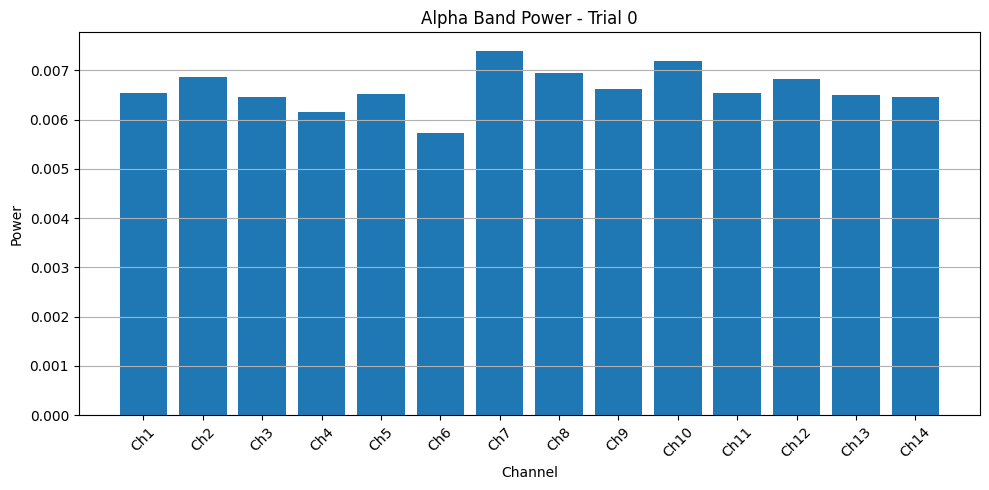

In [ ]:
import matplotlib.pyplot as plt

# Choose one trial
trial_idx = 0
channel_names = [f"Ch{i+1}" for i in range(14)]

# Reshape feature vector for that trial
trial_features = features[trial_idx].reshape(14, 9)

# Extract power band features (index 4 to 8 = delta to gamma)
bandpowers = trial_features[:, 4:]
alpha_power = bandpowers[:, 2]  # alpha band

# Plot Alpha Power for all 14 channels
plt.figure(figsize=(10, 5))
plt.bar(channel_names, alpha_power)
plt.title(f"Alpha Band Power - Trial {trial_idx}")
plt.xlabel("Channel")
plt.ylabel("Power")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


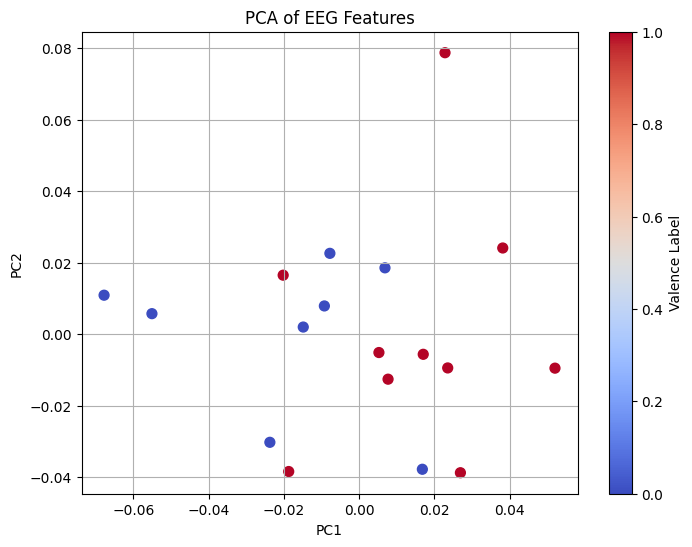

In [ ]:
from sklearn.decomposition import PCA
import numpy as np

# Optional: valence labels for coloring (use your actual label vector)
valence_labels = np.random.randint(0, 2, size=features.shape[0])  # binary example

# Reduce dimensions
pca = PCA(n_components=2)
reduced = pca.fit_transform(features)

# Plot
plt.figure(figsize=(8, 6))
scatter = plt.scatter(reduced[:, 0], reduced[:, 1], c=valence_labels, cmap='coolwarm', s=50)
plt.title("PCA of EEG Features")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(scatter, label="Valence Label")
plt.grid(True)
plt.show()


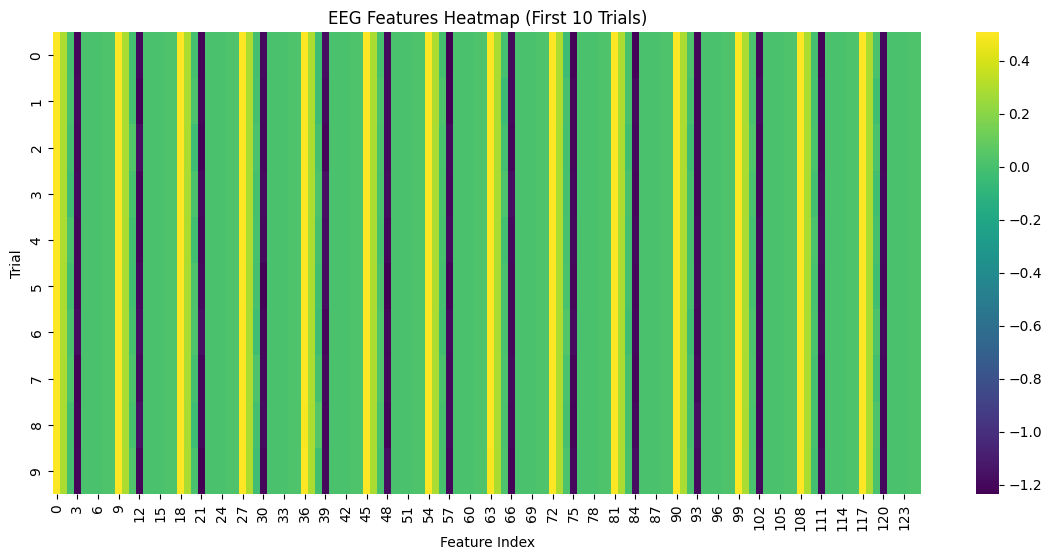

In [ ]:
import seaborn as sns

# Heatmap for first 10 trials
plt.figure(figsize=(14, 6))
sns.heatmap(features[:10], cmap='viridis', annot=False)
plt.title("EEG Features Heatmap (First 10 Trials)")
plt.xlabel("Feature Index")
plt.ylabel("Trial")
plt.show()


EEG shape: (25472, 14)
Creating RawArray with float64 data, n_channels=25472, n_times=14
    Range : 0 ... 13 =      0.000 ...     0.102 secs
Ready.


<Figure size 1500x1000 with 0 Axes>

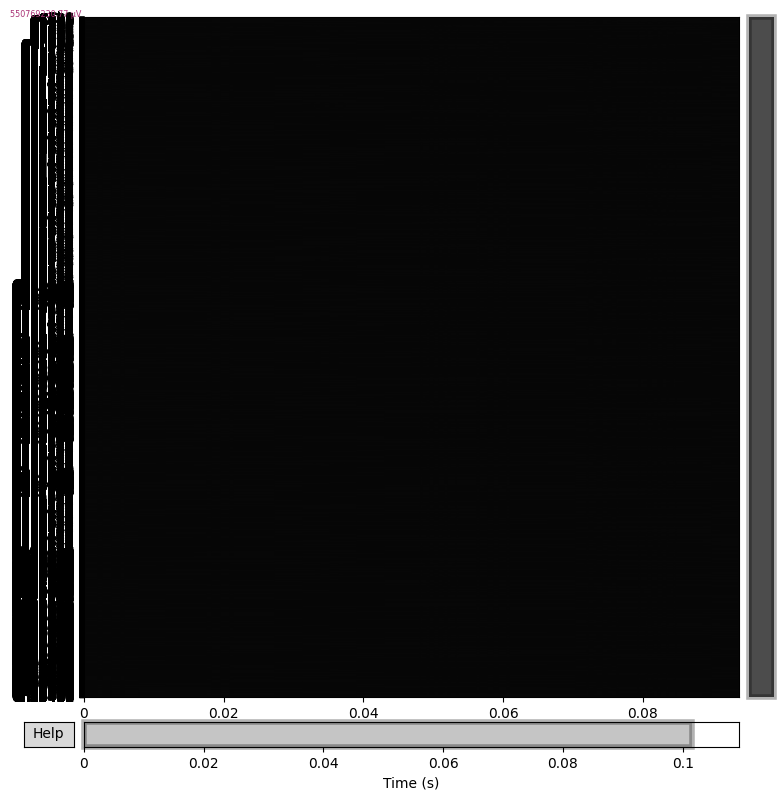

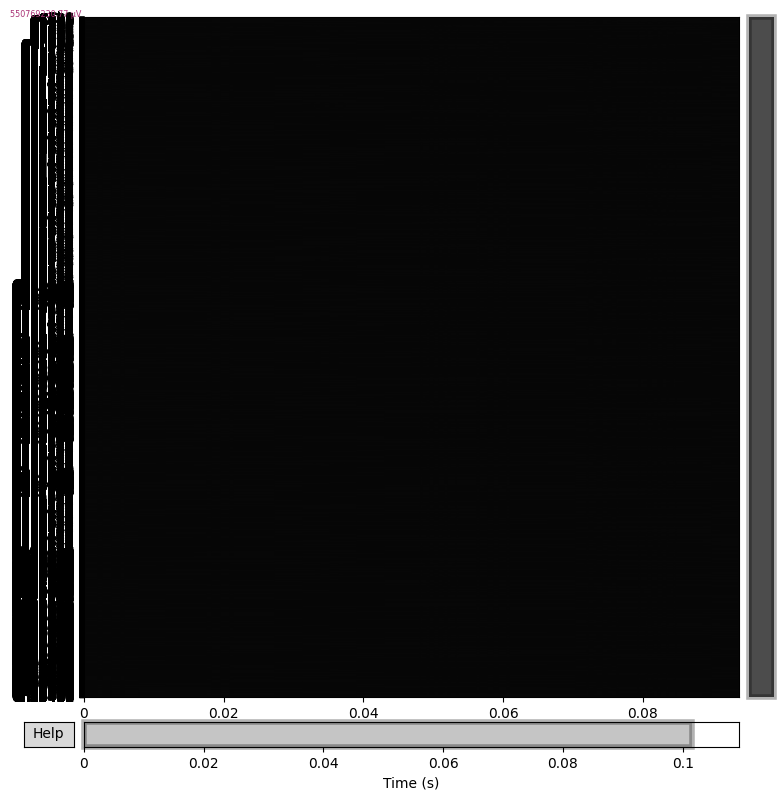

In [ ]:
!pip install mne

import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
import mne

# -----------------------------
# Load DREAMER Dataset
# -----------------------------
mat = sio.loadmat('/content/DREAMER.mat')

# Access the top-level DREAMER struct, which is an array of (1,1)
dreamer_struct = mat['DREAMER'][0][0] # Access the actual struct

# Choose subject & trial
subject = 0   # subject index (0–22)
trial = 0     # trial index (0–17)

# Extract subject's data from the 'Data' field of the DREAMER struct
subject_data_array = dreamer_struct['Data'][0] # This is an array of 23 subjects

# Get the specific subject's entry (it's also wrapped in a (1,) array)
specific_subject_entry = subject_data_array[subject][0]

# Access the 'EEG' field, then the first element of its (1,1) array, then the specific trial, and finally the 'stimuli' data
# This path extracts the 2D array of (N_channels, N_samples) directly.
raw_eeg = specific_subject_entry['EEG'][0][0][trial]['stimuli'][0][0]

# The previous line 'raw_eeg = np.vstack(raw_eeg_nested[:,0])' was causing the issue.
# 'raw_eeg' should now directly contain the (N_channels, N_samples) data.

print("EEG shape:", raw_eeg.shape)

# -----------------------------
# Prepare MNE Raw Object
# -----------------------------
fs = 128  # sampling rate
n_channels = raw_eeg.shape[0]

channel_names = [f"Ch{i+1}" for i in range(n_channels)]
channel_types = ["eeg"] * n_channels

info = mne.create_info(ch_names=channel_names, sfreq=fs, ch_types=channel_types)
raw = mne.io.RawArray(raw_eeg, info)

# -----------------------------
# Plot ALL Channel Raw Signals
# -----------------------------
plt.figure(figsize=(15, 10))
raw.plot(duration=10, n_channels=n_channels, scalings='auto', title="DREAMER Raw EEG Signals")